# EXP-003：建議人力門檻

> 實驗紀錄與結論：[EXP-003-manpower-thresholds.md](EXP-003-manpower-thresholds.md)

**背景：** 系統的最低門檻是「8 人、哨長 4 人」。每天 12 班 × 2 個位置 = 24 格，
每人每天最多 3 班（受 6 小時歇哨限制），8 × 3 = 24，剛好排得下。

**問題：** 情境模擬顯示 8 人全勤時每月仍有約 60 格空缺。最低門檻顯然只是必要條件，那要多少人才真的排得滿？

**方法：** 全勤 30 天，30 seeds：

1. 每日可動用 8～13 人（哨長占 60%）。
2. 20 人中哨長 4～7 人，記錄空缺落在哪個位置，以及「哨長位有空缺的日子，是否有哨長被排去站槍兵位」。

## 重現方式

```bash
npm run experiment -- scripts/experiments/exp-003-manpower-thresholds.ts    # 產生 data/exp-003/（人少時回溯搜尋較慢，約 10 分鐘）
.venv/Scripts/jupyter nbconvert --to notebook --execute --inplace docs/experiments/EXP-003-manpower-thresholds.ipynb
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nbutils import BLUE, INK, MUTED, ORANGE, load, mean_ci

runs = load("exp-003", "runs")
assert runs.violations.sum() == 0, "發現違規！"
print(f"runs: {len(runs)}, seeds: {runs.seed.nunique()}；✓ 違規數：0")
head = runs[runs.sweep == "headcount"]
lead = runs[runs.sweep == "leaders"]

runs: 300, seeds: 30；✓ 違規數：0


## 1. 每日可動用人數 vs 每月空缺

每個點是一個 seed 的單月空缺數；線為 30 seeds 平均。

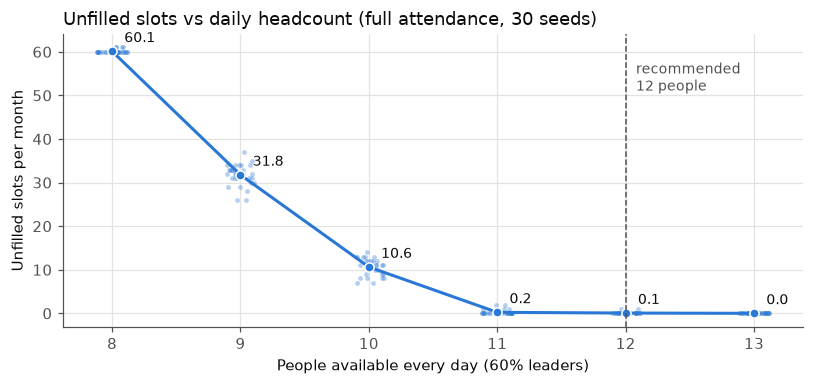

,,mean,worst,zero_gap_months
n_people,n_leaders,,,
8,5,60.1 ± 0.1,61,0%
9,5,31.8 ± 0.9,37,0%
10,6,10.6 ± 0.7,14,0%
11,7,0.2 ± 0.2,2,83%
12,7,0.1 ± 0.1,1,93%
13,8,0.0 ± 0.0,0,100%


In [2]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
rng = np.random.default_rng(0)
ax.scatter(head.n_people + rng.uniform(-0.12, 0.12, len(head)), head.gaps, s=10, color=BLUE, alpha=0.35, linewidths=0)
m = head.groupby("n_people").gaps.mean()
ax.plot(m.index, m.values, color=BLUE, lw=2, marker="o", ms=6, markeredgecolor="white")
for n, v in m.items():
    ax.annotate(f"{v:.1f}", (n, v), textcoords="offset points", xytext=(8, 6), color=INK, fontsize=9)
ax.axvline(12, color=MUTED, lw=1, ls="--")
ax.text(12.08, m.max() * 0.85, "recommended\n12 people", color=MUTED, fontsize=9)
ax.set_xlabel("People available every day (60% leaders)")
ax.set_ylabel("Unfilled slots per month")
ax.set_title("Unfilled slots vs daily headcount (full attendance, 30 seeds)")
plt.tight_layout()
plt.show()

head.groupby(["n_people", "n_leaders"]).gaps.agg(
    mean=lambda x: mean_ci(x, 1), worst="max", zero_gap_months=lambda x: f"{(x == 0).mean():.0%}")

### 為什麼 8 人不夠

剛好 8 人時，每人每天必須站滿 3 班，且歇哨規定使班次只能是 {0,4,8}、{1,5,9}、{2,6,10}、{3,7,11} 四種組合之一，
每種組合每天都需要剛好 2 人。跨日歇哨使每個人隔天的起始班次只能維持或往後移；起始班次只能往後、四種組合的人數又必須固定，
唯一的可能就是每個人每天都維持同一組合。四種組合中有三種包含灰色時段，因此有 6 人每天都站灰色，
第三天必然違反「不可連續三天灰色」。所以 8 人的空缺是規定本身造成的，不是演算法不夠好。

## 2. 哨長人數 vs 空缺位置（20 人全勤）

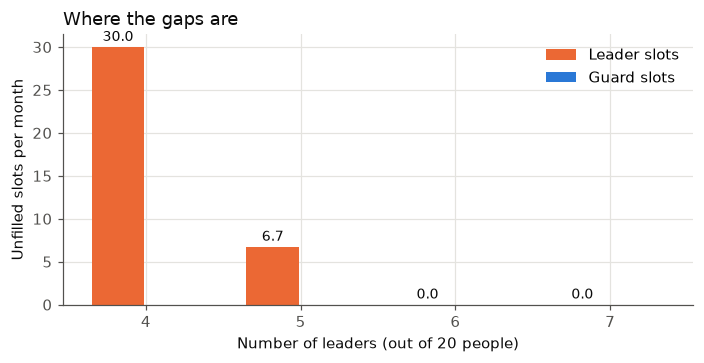

哨長位有空缺的日子，哨長被排在槍兵位的格數（30 seeds 合計）：
n_leaders
4    0.0
5    0.0
6    0.0
7    0.0


In [3]:
lg = lead.groupby("n_leaders")[["leader_gaps", "guard_gaps"]].mean()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(lg))
ax.bar(x - 0.18, lg.leader_gaps, width=0.34, color=ORANGE, label="Leader slots")
ax.bar(x + 0.18, lg.guard_gaps, width=0.34, color=BLUE, label="Guard slots")
for i, v in enumerate(lg.leader_gaps):
    ax.annotate(f"{v:.1f}", (i - 0.18, v), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9, color=INK)
ax.set_xticks(x, lg.index)
ax.set_xlabel("Number of leaders (out of 20 people)")
ax.set_ylabel("Unfilled slots per month")
ax.set_title("Where the gaps are")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

wasted = lead.groupby("n_leaders").leader_on_guard_with_gap.sum()
print("哨長位有空缺的日子，哨長被排在槍兵位的格數（30 seeds 合計）：")
print(wasted.to_string())

## 結論

- **最低門檻 8 人是必要但不充分的條件。** 9 人每月約 32 格空缺，10 人約 11 格，11 人以上趨近 0。
- **12 人時，30 個月中偶爾出現 1 格空缺**（平均每月約 0.1 格），因此「建議 12 人」是合理的提醒值，但不是保證。
- **哨長 6 人以上才不缺哨長。** 空缺全部落在哨長位。
- **空缺不是演算法浪費哨長造成的：** 哨長位有空缺的日子，從來沒有哨長被排去站槍兵位。
  MRV heuristic 會優先填滿候選人最少的位置。